# 외부 툴 사용

In [22]:
# Our favorite first step! Crew was doing this for us, by the way.
import os
from dotenv import load_dotenv

load_dotenv(override=True)

True

### First, let's go set up LangSmith!

https://langsmith.com

## serper.dev 동작 확인 테스트

### Next, here is a useful function in LangChain community:

In [21]:
from langchain_community.utilities import GoogleSerperAPIWrapper

serper = GoogleSerperAPIWrapper()
serper.run("What is the capital of France?")

'As the capital of France, Paris is the seat of France\'s national government ; Both houses of the French Parliament ; France\'s highest courts are located in Paris. What is the capital of FRANCE? 107K. Dislike. 4,337. Share. Video unavailable. This content isn\'t available. Skip video. Paris is the capital and most populous city of France. Situated on the Seine River, in the north of the country, it is in the centre of the Île-de-France ... France, country of northwestern Europe. Historically and culturally among the most important nations in the Western world. Paris is the capital of France, the largest country of Europe with 550 000 km2 (65 millions inhabitants). Paris has 2.234 million inhabitants end 2011. Paris is the city of romance par excellence, the fashion capital and the best example of French art de vivre. Exploring Paris is an essential rite of passage ... Paris is the capital and largest city of France, renowned globally for its cultural, historical, and artistic signifi

## langchain Tool 로 serper 사용

### Now here is a LangChain wrapper class for converting functions into Tools

In [10]:
from langchain_core.tools import Tool

tool_search =Tool(
        name="search",
        func=serper.run,
        description="Useful for when you need more information from an online search"
    )



### Now we can try out the tool the langchain way

In [11]:
tool_search.invoke("What is the capital of France?")

"As the capital of France, Paris is the seat of France's national government ; Both houses of the French Parliament ; France's highest courts are located in Paris. What is the capital of FRANCE? 107K. Dislike. 4,337. Share. Video unavailable. This content isn't available. Skip video. Paris is the capital and most populous city of France. Situated on the Seine River, in the north of the country, it is in the centre of the Île-de-France ... France, country of northwestern Europe. Historically and culturally among the most important nations in the Western world. Paris is the capital of France, the largest country of Europe with 550 000 km2 (65 millions inhabitants). Paris has 2.234 million inhabitants end 2011. Paris is the city of romance par excellence, the fashion capital and the best example of French art de vivre. Exploring Paris is an essential rite of passage ... PARIS it is the capital and largest city of France. Located on the Seine in the country's north, it is a major cultural 

### And now let's write a tool ourselves

We'll pick a familiar one

## LangChain Tool로 PushOver 사용

In [19]:
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_user = os.getenv("PUSHOVER_USER")
pushover_url = "https://api.pushover.net/1/messages.json"

def push(text: str):
    """Send a push notification to the user"""
    requests.post(pushover_url, data = {"token": pushover_token, "user": pushover_user, "message": text})

In [20]:
tool_push = Tool(
        name="send_push_notification",
        func=push,
        description="useful for when you want to send a push notification"
    )

tool_push.invoke("Hello, me")

# LangGraph Tool Calling & OpenAI Chat

### Back to the Graph from yesterday

One small change - using TypedDict instead of BaseModel for the State object

When we implement tools, we always need to make 2 changes to the code:

1. Changes to provide the tools to OpenAI in json when we make the call

2. Changes to handle the results back: look for the model staying that the finish_reason=="tool_calls" and then retrieve the call, run the function, provide the results.

### Bring them together

## Tooㅣ 설정

In [28]:
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import Tool

serper = GoogleSerperAPIWrapper()

tool_search =Tool(
        name="search",
        func=serper.run,
        description="Useful for when you need more information from an online search"
    )

In [29]:
import requests
import os
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_user = os.getenv("PUSHOVER_USER")
pushover_url = "https://api.pushover.net/1/messages.json"

def push(text: str):
    """Send a push notification to the user"""
    requests.post(pushover_url, data = {"token": pushover_token, "user": pushover_user, "message": text})

tool_push = Tool(
        name="send_push_notification",
        func=push,
        description="useful for when you want to send a push notification"
    )

In [30]:
tools = [tool_search, tool_push]

## Step 1: Define the State object

In [48]:
from typing import Annotated
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
from IPython.display import Image, display
import gradio as gr
from langgraph.prebuilt import ToolNode, tools_condition

from langchain_openai import ChatOpenAI
from typing import TypedDict

In [49]:
# Step 1: Define the State object
class State(TypedDict):
    messages: Annotated[list, add_messages]

## Step 2: Start the Graph Builder with this State class

In [50]:
# Step 2: Start the Graph Builder with this State class
graph_builder = StateGraph(State)

https://reference.langchain.com/python/langchain-core/language_models/chat_models/BaseChatModel/bind_tools


In [51]:
# This is different:

llm = ChatOpenAI(model="gpt-5-mini")
llm_with_tools = llm.bind_tools(tools)

## Step 3: Create a Node

In [52]:
# Step 3: Create a Node

def chatbot(state: State):
    response = llm_with_tools.invoke(state["messages"])  # LLM 호출 (tool 사용 여부 포함된 응답)

    # ---- tool 사용 여부 확인 및 출력 ----  # [포인트] 그래프 실행 중 디버깅용 로그
    if response.tool_calls:
        print(f"🔧 Tool 호출됨 (총 {len(response.tool_calls)}개)")
        for call in response.tool_calls:
            print(f"   - {call['name']}({call['args']})")  # 어떤 tool을 어떤 인자로 불렀는지
    else:
        print("💬 Tool 미사용 — LLM이 직접 답변")

    return {"messages": [response]}  # 상태에 응답 메시지 추가 (기존 로직 유지)


graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", ToolNode(tools=tools))

## Step 4: Create Edges

In [53]:
# Step 4: Create Edges


graph_builder.add_conditional_edges( "chatbot", tools_condition, "tools")

# Any time a tool is called, we return to the chatbot to decide the next step
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

## Step 5: Compile the Graph

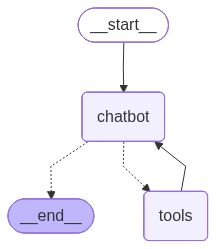

In [54]:
# Step 5: Compile the Graph
graph = graph_builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

### That's it! And, let's do this:

현재 서울 날씨 알려주고 알림 즉시 보내줘

In [56]:
def chat(user_input: str, history):
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]})
    return result["messages"][-1].content


gr.ChatInterface(chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


🔧 Tool 호출됨 (총 2개)
   - search({'__arg1': '서울 현재 날씨'})
   - send_push_notification({'__arg1': '현재 서울 날씨 알림: 잠시 후 자세한 정보를 확인하세요.'})


# OK it's time to add Memory!

### BUT WAIT!

We have this whole Graph maintaining the state and appending to the state.

Why isn't this handling memory?

### This is a crucial point for understanding LangGraph

> A super-step can be considered a single iteration over the graph nodes. Nodes that run in parallel are part of the same super-step, while nodes that run sequentially belong to separate super-steps.


One "Super-Step" of the graph represents one invocation of passing messages between agents.

In idomatic LangGraph, you call invoke to run your graph for each super-step; for each interaction.

The reducer handles state updates automatically within one super-step, but not between them.

That is what checkpointing achieves.

In [33]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

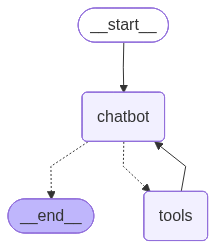

In [34]:
# Steps 1 and 2
graph_builder = StateGraph(State)


# Step 3
llm = ChatOpenAI(model="gpt-4o-mini")
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    print(state)
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", ToolNode(tools=tools))

# Step 4
graph_builder.add_conditional_edges( "chatbot", tools_condition, "tools")
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

# Step 5
graph = graph_builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [35]:
config = {"configurable": {"thread_id": "1"}}

def chat(user_input: str, history):
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]}, config=config)
    return result["messages"][-1].content


gr.ChatInterface(chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


{'messages': [HumanMessage(content='내 이름은 지노야', additional_kwargs={}, response_metadata={}, id='9e76424e-5b55-407f-81ca-072538570aaf')]}
{'messages': [HumanMessage(content='내 이름은 지노야', additional_kwargs={}, response_metadata={}, id='9e76424e-5b55-407f-81ca-072538570aaf'), AIMessage(content='안녕하세요, 지노님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 94, 'total_tokens': 109, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f9565ce549', 'id': 'chatcmpl-DU54SGx32u1kbOCIyj5Ps07DjAZr2', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--8b6a0bf2-67f9-42f0-8911-038806accdcd-0', usage_metadata={'input_tokens': 94, 'output_tokens': 15, 'total_tokens': 109, 'input_toke

In [38]:
graph.get_state(config)

StateSnapshot(values={'messages': [HumanMessage(content='내 이름은 지노야', additional_kwargs={}, response_metadata={}, id='9e76424e-5b55-407f-81ca-072538570aaf'), AIMessage(content='안녕하세요, 지노님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 94, 'total_tokens': 109, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f9565ce549', 'id': 'chatcmpl-DU54SGx32u1kbOCIyj5Ps07DjAZr2', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--8b6a0bf2-67f9-42f0-8911-038806accdcd-0', usage_metadata={'input_tokens': 94, 'output_tokens': 15, 'total_tokens': 109, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}), HumanMessage(cont

In [39]:
# Most recent first

list(graph.get_state_history(config))

[StateSnapshot(values={'messages': [HumanMessage(content='내 이름은 지노야', additional_kwargs={}, response_metadata={}, id='9e76424e-5b55-407f-81ca-072538570aaf'), AIMessage(content='안녕하세요, 지노님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 94, 'total_tokens': 109, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f9565ce549', 'id': 'chatcmpl-DU54SGx32u1kbOCIyj5Ps07DjAZr2', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--8b6a0bf2-67f9-42f0-8911-038806accdcd-0', usage_metadata={'input_tokens': 94, 'output_tokens': 15, 'total_tokens': 109, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}), HumanMessage(con

### LangGraph gives you tools to set the state back to a prior point in time, to branch off:

```
config = {"configurable": {"thread_id": "1", "checkpoint_id": ...}}
graph.invoke(None, config=config)
```

And this allows you to build stable systems that can be recovered and rerun from any prior checkpoint.

# And now let's store in SQL

### And this is the power of LangGraph.

In [40]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

db_path = "memory.db"
conn = sqlite3.connect(db_path, check_same_thread=False)
sql_memory = SqliteSaver(conn)

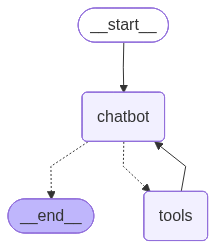

In [41]:
# Steps 1 and 2
graph_builder = StateGraph(State)


# Step 3
llm = ChatOpenAI(model="gpt-4o-mini")
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    print(state)
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", ToolNode(tools=tools))

# Step 4
graph_builder.add_conditional_edges( "chatbot", tools_condition, "tools")
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")

# Step 5
graph = graph_builder.compile(checkpointer=sql_memory)
display(Image(graph.get_graph().draw_mermaid_png()))
 

In [43]:
config = {"configurable": {"thread_id": "3"}}

def chat(user_input: str, history):
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]}, config=config)
    return result["messages"][-1].content


gr.ChatInterface(chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7866
* To create a public link, set `share=True` in `launch()`.


{'messages': [HumanMessage(content='hi there', additional_kwargs={}, response_metadata={}, id='d6144090-9963-438c-b21b-3fb4f06edbc0'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 90, 'total_tokens': 101, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_b376dfbbd5', 'id': 'chatcmpl-BInN7JUnEYNTQqokCF3eihp5oKP0V', 'finish_reason': 'stop', 'logprobs': None}, id='run-4b488710-73ac-435e-a944-913a0c812d08-0', usage_metadata={'input_tokens': 90, 'output_tokens': 11, 'total_tokens': 101, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}), HumanMessage(content="what's my name", additional_kwargs